# Predicting Dengue Outbreaks in Bangladesh from Climate Data
**Real data only:** DGHS monthly dengue cases (2001–2024) + NASA POWER weather for Dhaka.
This notebook runs the complete study end-to-end: EDA → feature engineering → 6 regression models → cross-validation → hyperparameter tuning → outbreak classification → SHAP explainability.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 120)
df = pd.read_csv('data/dengue_weather_monthly.csv', parse_dates=['year_month'])
print('Shape:', df.shape)
df.head()

Shape: (288, 6)


,year_month,cases,date,temperature_c,humidity_pct,rainfall_mm_day
0,2001-01-01,0,2001-01-01,16.39,56.78,0.00
1,2001-02-01,0,2001-02-01,21.75,46.08,1.30
2,2001-03-01,0,2001-03-01,26.57,41.35,0.73
3,2001-04-01,0,2001-04-01,30.85,49.74,2.55
4,2001-05-01,5,2001-05-01,28.76,80.47,11.52


In [2]:
df.describe().round(2)

,year_month,cases,temperature_c,humidity_pct,rainfall_mm_day
count,288,288.00,288.00,288.00,288.00
mean,2012-12-15 17:00:00,2295.06,25.50,75.08,6.11
min,2001-01-01 00:00:00,0.00,15.39,41.35,0.00
25%,2006-12-24 06:00:00,0.00,22.25,65.16,0.71
50%,2012-12-16 12:00:00,59.50,27.56,79.19,4.83
75%,2018-12-08 18:00:00,387.50,28.50,88.04,9.72
max,2024-12-01 00:00:00,79598.00,31.86,91.51,28.39
std,NaN,9375.74,4.16,13.99,5.96


In [3]:
df['year'] = df['year_month'].dt.year
yearly = df.groupby('year')['cases'].sum().rename('total_cases')
print('Total cases 2001-2024:', int(yearly.sum()))
yearly.tail(8)

Total cases 2001-2024: 660976


year
2017      2769
2018     10148
2019    101354
2020      1193
2021     28429
2022     62382
2023    321179
2024    101214
Name: total_cases, dtype: int64

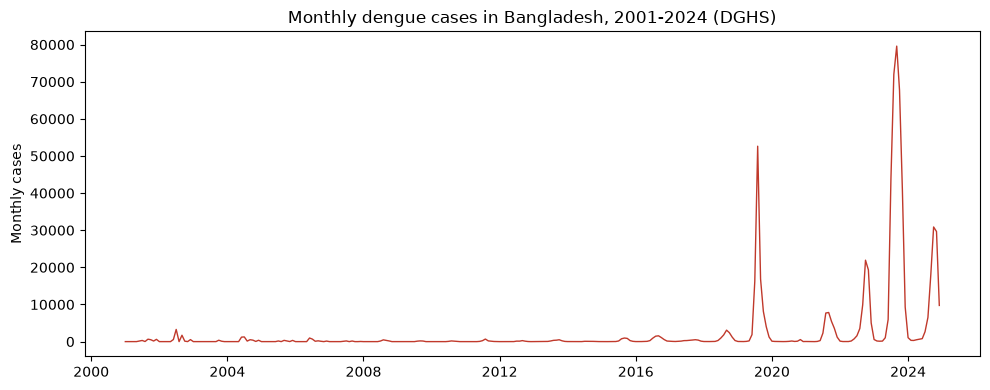

In [4]:
plt.figure(figsize=(10,4))
plt.plot(df['year_month'], df['cases'], color='#c0392b', lw=1)
plt.ylabel('Monthly cases'); plt.title('Monthly dengue cases in Bangladesh, 2001-2024 (DGHS)')
plt.tight_layout(); plt.show()

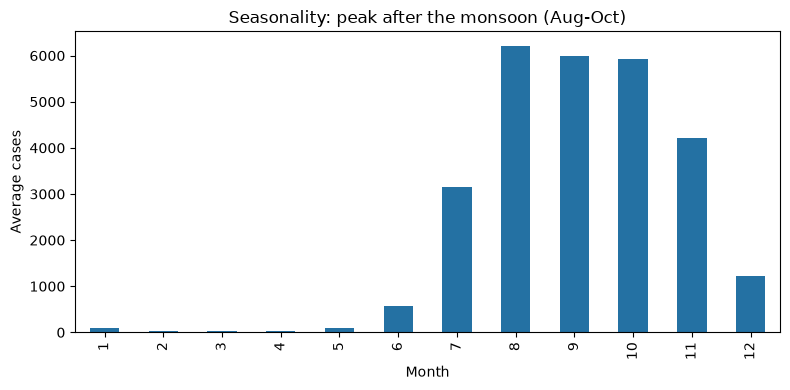

In [5]:
plt.figure(figsize=(8,4))
df.groupby(df['year_month'].dt.month)['cases'].mean().plot(kind='bar', color='#2471a3')
plt.ylabel('Average cases'); plt.xlabel('Month'); plt.title('Seasonality: peak after the monsoon (Aug-Oct)')
plt.tight_layout(); plt.show()

## Feature engineering
Dengue follows rain with a lag (mosquito breeding). We add rainfall lags 1–3, temperature/humidity lag 1, case lags 1 and 12, and month seasonality. Target: `log1p(cases)` because counts range 0–79,598.
**Split is time-based** (train ≤2019, test 2020–2024) — random splits leak the future.

In [6]:
df['month'] = df['year_month'].dt.month
df['month_sin'] = np.sin(2*np.pi*df['month']/12); df['month_cos'] = np.cos(2*np.pi*df['month']/12)
for lag in (1,2,3): df[f'rain_lag{lag}'] = df['rainfall_mm_day'].shift(lag)
df['temp_lag1'] = df['temperature_c'].shift(1); df['hum_lag1'] = df['humidity_pct'].shift(1)
df['cases_lag1'] = df['cases'].shift(1); df['cases_lag12'] = df['cases'].shift(12)
df['log_cases'] = np.log1p(df['cases'])
d = df.dropna().reset_index(drop=True)
FEATS = ['temperature_c','humidity_pct','rainfall_mm_day','rain_lag1','rain_lag2','rain_lag3','temp_lag1','hum_lag1','cases_lag1','cases_lag12','month_sin','month_cos']
tr = d['year_month'] <= '2019-12-31'; te = ~tr
print('train months:', int(tr.sum()), '| test months:', int(te.sum()))

train months: 216 | test months: 60


## Task 1 — predict monthly cases (6 models)

In [7]:
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
X, y = d[FEATS], d['log_cases']
MODELS = {'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
 'Decision Tree': DecisionTreeRegressor(random_state=42),
 'K-Nearest Neighbours': make_pipeline(StandardScaler(), KNeighborsRegressor(7)),
 'Support Vector Regression': make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.1)),
 'Random Forest': RandomForestRegressor(n_estimators=400, random_state=42, n_jobs=-1),
 'Gradient Boosting': HistGradientBoostingRegressor(random_state=42)}
rows = {}
for name, m in MODELS.items():
    m.fit(X[tr], y[tr]); p = np.expm1(m.predict(X[te]))
    rows[name] = {'MAE': round(mean_absolute_error(d.loc[te,'cases'], p),1), 'R2 (log)': round(r2_score(y[te], np.log1p(p)),4)}
    if name == 'Random Forest': rf, rf_pred = m, p
pd.DataFrame(rows).T.sort_values('R2 (log)', ascending=False)

,MAE,R2 (log)
Random Forest,6886.1,0.6822
Gradient Boosting,7627.2,0.5915
Linear Regression,55559.0,-0.0699
Decision Tree,7142.8,-0.1802
K-Nearest Neighbours,8389.2,-0.5263
Support Vector Regression,8302.0,-0.7911


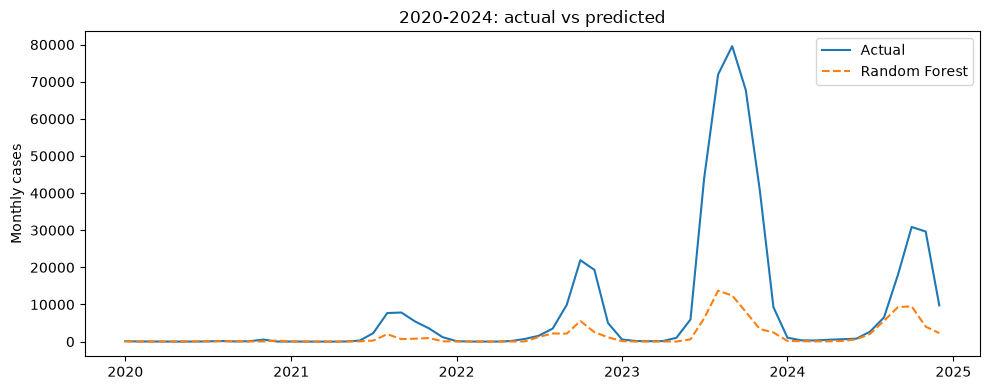

In [8]:
plt.figure(figsize=(10,4))
plt.plot(d.loc[te,'year_month'].values, d.loc[te,'cases'].values, label='Actual')
plt.plot(d.loc[te,'year_month'].values, rf_pred, label='Random Forest', ls='--')
plt.ylabel('Monthly cases'); plt.legend(); plt.title('2020-2024: actual vs predicted')
plt.tight_layout(); plt.show()

## Cross-validation + tuning (training period only, TimeSeriesSplit)

In [9]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
tscv = TimeSeriesSplit(n_splits=5)
for name in ['Random Forest','Gradient Boosting']:
    s = cross_val_score(MODELS[name], X[tr], y[tr], cv=tscv, scoring='r2', n_jobs=-1)
    print(name, 'CV R2: %.3f +- %.3f' % (s.mean(), s.std()))
grid = {'n_estimators':[300,600], 'max_depth':[None,10,20], 'min_samples_leaf':[1,2]}
gs = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1), grid, cv=TimeSeriesSplit(3), scoring='r2', n_jobs=-1)
gs.fit(X[tr], y[tr])
print('Best params:', gs.best_params_)
p = np.expm1(gs.predict(X[te]))
print('Tuned RF test R2 (log):', round(r2_score(y[te], np.log1p(p)),4))

Random Forest CV R2: 0.258 +- 0.430
Gradient Boosting CV R2: 0.290 +- 0.202


Best params: {'max_depth': None, 'min_samples_leaf': 2, 'n_estimators': 300}
Tuned RF test R2 (log): 0.7014


## Task 2 — predict outbreak months (cases ≥ 5,000)

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score
d['outbreak'] = (d['cases'] >= 5000).astype(int); yc = d['outbreak']
CLFS = {'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
 'Random Forest': RandomForestClassifier(n_estimators=400, random_state=42, n_jobs=-1),
 'Gradient Boosting': HistGradientBoostingClassifier(random_state=42)}
rows = {}
for name, m in CLFS.items():
    m.fit(X[tr], yc[tr]); pr = m.predict(X[te]); pb = m.predict_proba(X[te])[:,1]
    rows[name] = {'Accuracy': round(accuracy_score(yc[te], pr),4), 'ROC-AUC': round(roc_auc_score(yc[te], pb),4), 'F1': round(f1_score(yc[te], pr),4)}
pd.DataFrame(rows).T

,Accuracy,ROC-AUC,F1
Logistic Regression,0.7833,0.8883,0.6667
Random Forest,0.7667,0.9101,0.4167
Gradient Boosting,0.7500,0.9243,0.3478


## SHAP — why does the model predict this?

/home/hatch/workspace/.venvs/realenv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


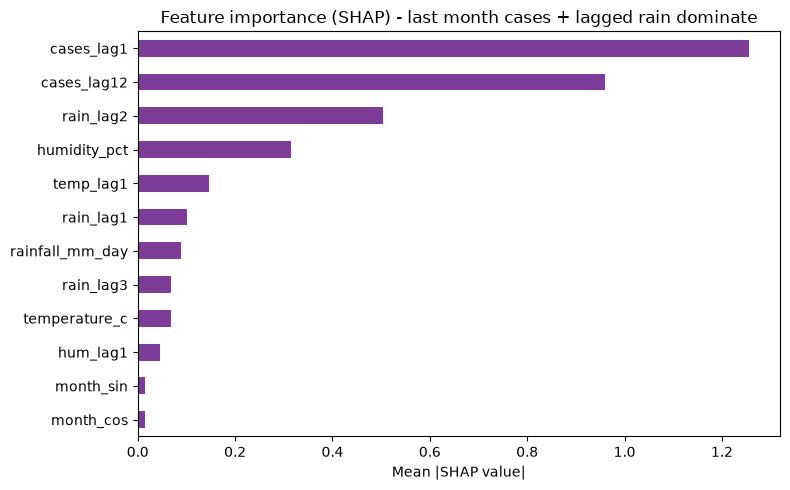

In [11]:
import shap
sv = shap.TreeExplainer(rf).shap_values(X[te])
imp = pd.Series(np.abs(sv).mean(axis=0), index=FEATS).sort_values()
plt.figure(figsize=(8,5)); imp.plot(kind='barh', color='#7d3c98')
plt.xlabel('Mean |SHAP value|'); plt.title('Feature importance (SHAP) - last month cases + lagged rain dominate')
plt.tight_layout(); plt.show()

## Findings
1. Random Forest is the best case-count model (R² ≈ 0.68; tuned ≈ 0.70). Simple models (KNN, SVR, single tree) fail on outbreak scale — a real-data lesson.
2. Outbreak detection is strong: Gradient Boosting ROC-AUC ≈ 0.92, Random Forest ≈ 0.91 — comparable to Rahman & Shiddik (2025), XGBoost 0.89.
3. SHAP: `cases_lag1` and lagged rainfall drive predictions → a 1–2 month early-warning window is realistic.
4. Limitation: national monthly data hides district variation; 2023's peak is still underestimated.